In [2]:
%pip install scikit-learn


   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 2.0 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.2 MB 2.6 MB/s eta 0:00:03
   ------- -------------------------------- 1.6/8.2 MB 2.4 MB/s eta 0:00:03
   ---------- ----------------------------- 2.1/8.2 MB 2.7 MB/s eta 0:00:03
   ------------ --------------------------- 2.6/8.2 MB 2.5 MB/s eta 0:00:03
   --------------- ------------------------ 3.1/8.2 MB 2.4 MB/s eta 0:00:03
   ------------------- -------------------- 3.9/8.2 MB 2.6 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.2 MB 2.6 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.2 MB 2.6 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.2 MB 2.4 MB/s eta 0:00:02
   -------------------------- ------------- 5.5/8.2 MB 2.4 MB/s eta 0:00:02
   ----------------------------- ---------- 6.0/8.2 MB 2.4 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
# Load Dataset
df = pd.read_excel("Dataset/Online Retail.xlsx")

# Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
print("Dataset Shape:", df.shape)

Dataset Shape: (541909, 8)


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [11]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [12]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [13]:
# Check missing values
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [14]:
# Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

print("Missing values removed!")
print("Remaining rows:", df.shape[0])

Missing values removed!
Remaining rows: 406829


In [15]:
# Remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Remove negative and zero quantities
df = df[df['Quantity'] > 0]

# Remove zero and negative prices
df = df[df['UnitPrice'] > 0]

print("Data cleaning completed!")
print("Final Dataset Shape:", df.shape)

Data cleaning completed!
Final Dataset Shape: (397884, 8)


In [16]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [17]:
# Calculate total purchase amount

df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [18]:
# Convert InvoiceDate to datetime

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print("Date conversion completed!")

Date conversion completed!


In [19]:
# Convert InvoiceDate to datetime

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print("Date conversion completed!")

Date conversion completed!


In [20]:
# Set reference date

reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [21]:
# Perform RFM Analysis

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [22]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


In [23]:
# Select RFM features

rfm_features = rfm[['Recency', 'Frequency', 'Monetary']]

# Apply StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

print("Data Standardisation Completed!")

Data Standardisation Completed!


In [24]:
# Convert scaled data into DataFrame

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334574,-0.425097,8.358668
12347.0,-0.905340,0.354417,0.250966
12348.0,-0.175360,-0.035340,-0.028596
12349.0,-0.735345,-0.425097,-0.033012
12350.0,2.174578,-0.425097,-0.191347


In [25]:
rfm_scaled.describe()

,Recency,Frequency,Monetary
count,4.338000e+03,4.338000e+03,4.338000e+03
mean,2.702618e-17,1.801745e-17,1.801745e-17
std,1.000115e+00,1.000115e+00,1.000115e+00
min,-9.153401e-01,-4.250965e-01,-2.281344e-01
25%,-7.453445e-01,-4.250965e-01,-1.943495e-01
50%,-4.153533e-01,-2.951776e-01,-1.535104e-01
75%,4.946227e-01,9.457903e-02,-4.367134e-02
max,2.814561e+00,2.659803e+01,3.094634e+01


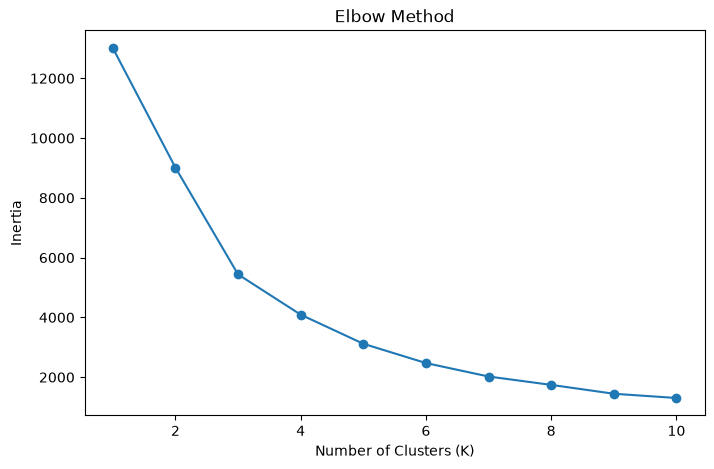

In [26]:
# Elbow Method

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Graph

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [27]:
# Apply K-Means Clustering

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means Clustering Completed!")

rfm.head()

K-Means Clustering Completed!


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,3
12347.0,2,7,4310.00,0
12348.0,75,4,1797.24,0
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,1


In [28]:
# Count customers in each cluster

print(rfm['Cluster'].value_counts().sort_index())

Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


In [29]:
# Calculate average values for each cluster

cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

cluster_profile

,Recency,Frequency,Monetary
Cluster,,,
0,43.70,3.68,1359.05
1,248.08,1.55,480.62
2,7.38,82.54,127338.31
3,15.50,22.33,12709.09


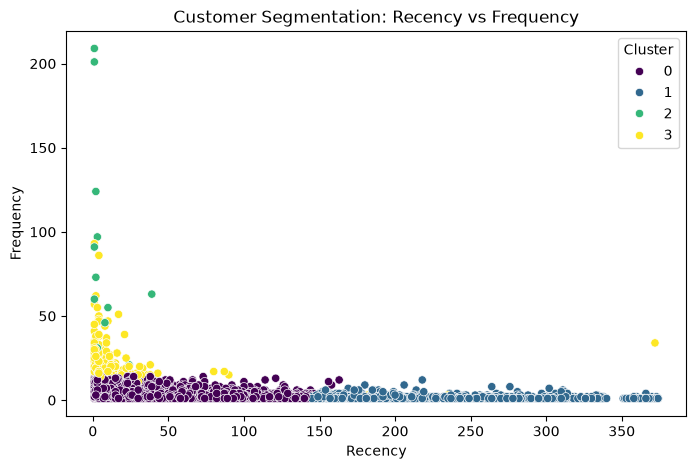

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis'
)

plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency')
plt.ylabel('Frequency')
plt.show()

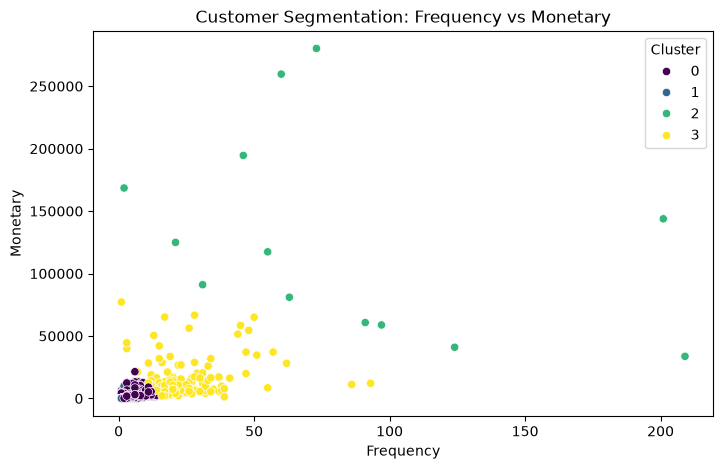

In [31]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis'
)

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Frequency')
plt.ylabel('Monetary')
plt.show()

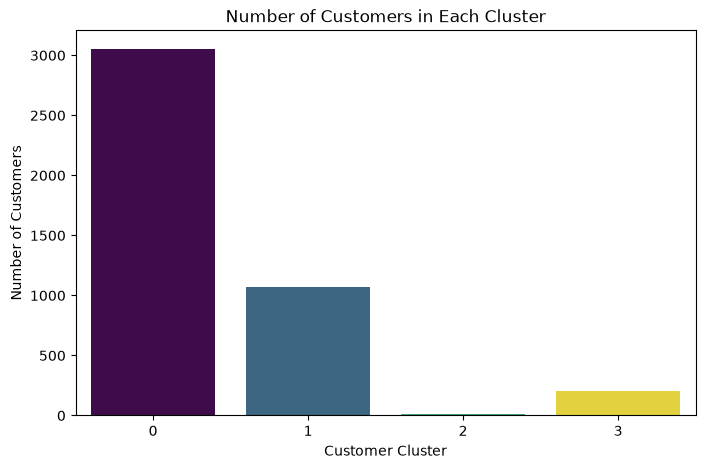

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.show()

In [33]:
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

print("Customer Segment Analysis:")
display(cluster_profile)

Customer Segment Analysis:


,Recency,Frequency,Monetary
Cluster,,,
0,43.70,3.68,1359.05
1,248.08,1.55,480.62
2,7.38,82.54,127338.31
3,15.50,22.33,12709.09


In [34]:
final_summary = rfm.groupby('Cluster').agg(
    Total_Customers=('Cluster', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean')
).round(2)

display(final_summary)

,Total_Customers,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,3054,43.70,3.68,1359.05
1,1067,248.08,1.55,480.62
2,13,7.38,82.54,127338.31
3,204,15.50,22.33,12709.09


CUSTOMER SEGMENTATION – MARKETING INSIGHTS

Cluster 0:
Target customers with loyalty rewards and special discounts.

Cluster 1:
Target inactive customers with reactivation emails and offers.

Cluster 2:
Reward high-value customers with premium offers and VIP memberships.

Cluster 3:
Encourage repeat purchases through promotional offers and discounts.

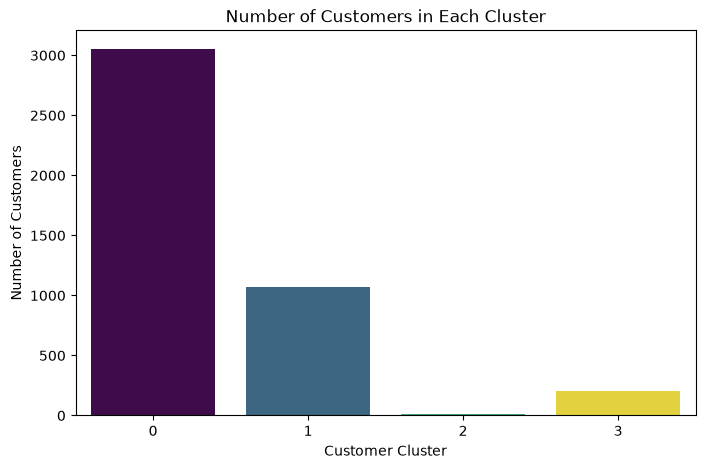

In [36]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()

In [37]:
# Marketing Insights

for cluster, row in cluster_profile.iterrows():

    print(f"\nCluster {cluster}")
    print("Recency:", row['Recency'])
    print("Frequency:", row['Frequency'])
    print("Monetary:", row['Monetary'])

    if row['Recency'] <= 30 and row['Frequency'] >= 10:
        print("Customer Type: Loyal Customers")
        print("Marketing: Give loyalty rewards and exclusive offers.")

    elif row['Recency'] > 180:
        print("Customer Type: Inactive Customers")
        print("Marketing: Send reactivation emails and special discounts.")

    elif row['Monetary'] >= 10000:
        print("Customer Type: High Value Customers")
        print("Marketing: Provide premium offers and VIP membership.")

    else:
        print("Customer Type: Regular Customers")
        print("Marketing: Encourage repeat purchases with discounts.")


Cluster 0
Recency: 43.7
Frequency: 3.68
Monetary: 1359.05
Customer Type: Regular Customers
Marketing: Encourage repeat purchases with discounts.

Cluster 1
Recency: 248.08
Frequency: 1.55
Monetary: 480.62
Customer Type: Inactive Customers
Marketing: Send reactivation emails and special discounts.

Cluster 2
Recency: 7.38
Frequency: 82.54
Monetary: 127338.31
Customer Type: Loyal Customers
Marketing: Give loyalty rewards and exclusive offers.

Cluster 3
Recency: 15.5
Frequency: 22.33
Monetary: 12709.09
Customer Type: Loyal Customers
Marketing: Give loyalty rewards and exclusive offers.
